# Real-Time PI Data Retrieval & Press 1 Quality Analysis

This notebook retrieves real-time process & lab quality data via the **MI Cube API** (`InterpolatedValue/MultiTag/`) from the **AVEVA PI Server (`VPKGDRBPPI01`)**.
The goal is to analyze **Press 1 pulp quality** (Kappa, Viscosity, Brightness) and plot **Probability Density Bell Curves** and **Heatmaps** directly.

In [ ]:
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style with thinner font weight
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['Tahoma', 'DejaVu Sans']
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['axes.titleweight'] = 'normal'
plt.rcParams['axes.labelweight'] = 'normal'
plt.rcParams['axes.unicode_minus'] = False
print(" Libraries imported successfully.")

 Libraries imported successfully.


## 1. Configure API Endpoint & Target PI Tags

In [28]:
import os
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))  # reads .env from the project root (searched upward from this folder)

# MI Cube API Endpoint for multi-tag interpolated data retrieval
MI_CUBE_API_URL = "https://micube.scg.com/v2/api/Datacenter/PIServer/InterpolatedValue/MultiTag/"
API_TOKEN = os.environ["MI_CUBE_API_TOKEN"]
PI_SERVER = "VPKGDRBPPI01"

# Target PI Tags (Batch Statuses + Press 1 Lab Quality Metrics)
TAGS = [
    "PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status",
    "PULP-LINE2-KAPPA-PRESS1",
    "PULP-LINE2-VISCOSITY-PRESS1",
    "PULP-LINE2-BRIGHTNESS-PRESS1",
    "PM2.105FIC303:MV", # WHLiqu to DilSrew
    "PM2.305FIC036:MV",  # MP Steam Pulp Heat
    "PM2.104FIQ507", #LP Steam
    "PM2.Prod.ODL", # Production ODL
    "PM2.105NIC207:MV", #Press 1 Feed Cons
    "PM2.106FIC006:MV", #Deknotting Feed Flow
    
]

# Time range settings
START_TIME = "2026-07-01 00:00:00"
END_TIME = "2026-10-01 00:00:00"
INTERVAL = "1h"

# Real quality SOP limits (Lower, Upper) — single source of truth used across all cells
LAB_SOP_LIMITS = {
    "PULP-LINE2-KAPPA-PRESS1": (7.5, 8.5),
    "PULP-LINE2-VISCOSITY-PRESS1": (680, 710),
    "PULP-LINE2-BRIGHTNESS-PRESS1": (37, 40),
}

print(f"Target Endpoint : {MI_CUBE_API_URL}")
print(f"Total Tags      : {len(TAGS)}")

Target Endpoint : https://micube.scg.com/v2/api/Datacenter/PIServer/InterpolatedValue/MultiTag/
Total Tags      : 13


## 2. Execute HTTP POST Request to MI Cube API

In [29]:
payload = {
    "token": API_TOKEN,
    "server": PI_SERVER,
    "tags": TAGS,
    "start_time": START_TIME,
    "end_time": END_TIME,
    "interval": INTERVAL
}

headers = {
    'Content-Type': 'application/json',
    'Accept': 'application/json'
}
    
print("Sending POST Request to MI Cube API...")
try:
    response = requests.post(MI_CUBE_API_URL, json=payload, headers=headers, timeout=30)
    print(f"Status Code: {response.status_code}")
    if response.status_code == 200:
        data = response.json()
        print(" Fetch Success! Response Preview:")
        print(json.dumps(data, indent=2)[:500])
    else:
        print(f" API Request Failed: {response.text}")
except Exception as e:
    print(f" Connection Error: {e}")

Sending POST Request to MI Cube API...
Status Code: 200
 Fetch Success! Response Preview:
{
  "status": "success",
  "message": "Interpolated values retrieved successfully",
  "results": {
    "PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status": [
      {
        "timestamp": "2026-07-01T00:00:00+00:00",
        "value": 1,
        "description": "",
        "unit": ""
      },
      {
        "timestamp": "2026-07-01T01:00:00+00:00",
        "value": 0.018086857142857144,
        "description": "",
        "unit": ""
      },
      {
        "timestamp": "2026-07-01T02:00:00+00:0


## 3. Parse JSON Response into Pandas DataFrame

In [30]:
if 'response' in locals() and response.status_code == 200:
    # Parse JSON structure
    if isinstance(data, dict) and 'results' in data:
        raw_results = data['results']
    elif isinstance(data, list):
        raw_results = data
    else:
        raw_results = [data]
        
    # Standardize long-format DataFrame
    if isinstance(raw_results, dict):
        df_list = []
        for tag, records in raw_results.items():
            tmp = pd.DataFrame(records)
            tmp['tag'] = tag
            df_list.append(tmp)
        df_long = pd.concat(df_list, ignore_index=True)
    else:
        df_long = pd.DataFrame(raw_results)
        
    print(f" Raw Data Parsed: {len(df_long)} records.")
    display(df_long.head(10))
else:
    print(" No response data available to process.")

 Raw Data Parsed: 28717 records.


,timestamp,value,description,unit,tag
0,2026-07-01T00:00:00+00:00,1,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
1,2026-07-01T01:00:00+00:00,0.018087,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
2,2026-07-01T02:00:00+00:00,0.044555,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
3,2026-07-01T03:00:00+00:00,0.071024,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
4,2026-07-01T04:00:00+00:00,1,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
5,2026-07-01T05:00:00+00:00,0.143855,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
6,2026-07-01T06:00:00+00:00,0.094995,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
7,2026-07-01T07:00:00+00:00,0.046136,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
8,2026-07-01T08:00:00+00:00,0.939076,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
9,2026-07-01T09:00:00+00:00,0.965923,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...


## 4. Press 1 Pulp Quality Analysis & Bell Curve Visualizations

In [31]:
# Data Reshaping, Specific Consumption Calculation & Active Digester Assignment
if 'df_long' in locals() and not df_long.empty:
    # 1. Standardize column names
    col_map = {col: col.lower() for col in df_long.columns}
    df_long = df_long.rename(columns=col_map)
    
    # 2. Pivot long format to wide format (Timestamp as Index, Tags as Columns)
    time_col = 'timestamp' if 'timestamp' in df_long.columns else 'time'
    tag_col = 'tag' if 'tag' in df_long.columns else 'tagname'
    val_col = 'value' if 'value' in df_long.columns else 'val'
    
    df_wide = df_long.pivot_table(index=time_col, columns=tag_col, values=val_col, aggfunc='first').reset_index()
    df_wide[time_col] = pd.to_datetime(df_wide[time_col])
    df_wide = df_wide.sort_values(time_col).reset_index(drop=True)
    
    # 3. Coerce numeric columns
    for col in df_wide.columns:
        if col != time_col:
            df_wide[col] = pd.to_numeric(df_wide[col], errors='coerce')
            
    # 4. Map Active Digester (1 - 4) — ใช้กฎเดียวกับ analytics platform (Digester Rule v1)
    #    engine : <platform>/analysis-service/app/pipeline/classify.py
    #    กฎ     : <platform>/web/data/projects/<project>.json → classDefs["press1-digester"]
    #    ย้ายโฟลเดอร์ platform → แก้ PLATFORM_DIR ที่เดียว
    import sys, json
    from pathlib import Path
    PLATFORM_DIR = Path("D:/chinnput/analytics platform")
    PLATFORM_PROJECT = "golden-batch"
    CLASS_DEF_ID = "press1-digester"

    status_cols = {
        1: 'PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status',
        2: 'PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status',
        3: 'PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status',
        4: 'PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status'
    }
    # definition สำรอง (ตรงกับ preset ใน platform) — ใช้เมื่ออ่านไฟล์ project ไม่ได้
    digester_def = {
        "id": CLASS_DEF_ID, "type": "one-hot", "noneLabel": "D0",
        "classes": [{"label": f"D{k}", "tag": c, "activeValue": k} for k, c in status_cols.items()],
    }
    try:
        project = json.loads((PLATFORM_DIR / "web" / "data" / "projects" / f"{PLATFORM_PROJECT}.json").read_text(encoding="utf-8"))
        digester_def = next(d for d in project.get("classDefs", []) if d["id"] == CLASS_DEF_ID)
        print(f" Class definition: {PLATFORM_PROJECT}/{CLASS_DEF_ID} (from platform)")
    except Exception as e:
        print(f" ⚠ อ่าน class definition จาก platform ไม่ได้ ({e}) → ใช้ definition สำรองใน cell นี้")

    try:
        sys.path.insert(0, str(PLATFORM_DIR / "analysis-service"))
        from app.pipeline.classify import classify
        labels = classify(df_wide, digester_def)
        # D1-D4 → 1-4 ให้ cell อื่นใช้ต่อได้เหมือนเดิม · D0 (ไม่มีหม้อ) / NaN (ซ้อน) → NaN
        label_to_id = {c["label"]: k for k, c in enumerate(digester_def["classes"], start=1)}
        df_wide['Digester_ID'] = labels.map(label_to_id).astype(float)
    except Exception as e:
        print(f" ⚠ import classify จาก platform ไม่ได้ ({e}) → ใช้กฎเดิมใน cell นี้")

        def get_active_digester(row):
            # Status must equal its own digester number exactly (B1 == 1, B2 == 2, ...)
            matches = [dig_id for dig_id, col in status_cols.items() if col in row and row[col] == dig_id]
            if len(matches) == 1:
                return matches[0]
            return np.nan  # NaN if no digester matches, or more than one (cannot tell which)

        df_wide['Digester_ID'] = df_wide.apply(get_active_digester, axis=1)

    # 5. Compute Specific Consumption Metrics (Specific White Liquor & Specific Steam)
    wl_tag = "PM2.105FIC303:MV"
    steam_tag = "PM2.305FIC036:MV"
    prod_tag = "PM2.Prod.ODL"

    if prod_tag in df_wide.columns:
        temp_prod = df_wide[prod_tag].copy()
        temp_prod[temp_prod <= 0] = np.nan
        
        if wl_tag in df_wide.columns:
            df_wide['Specific WHLiqu Consumption (m3_ADT)'] = 24.0 * df_wide[wl_tag] / temp_prod
        if steam_tag in df_wide.columns:
            df_wide['Specific Steam Consumption (t_ADT)'] = 24.0 * df_wide[steam_tag] / temp_prod

    print(" Real-time API Data Reshaped & Digester Assigned Successfully.")
    print("Batch Counts per Digester:")
    print(df_wide['Digester_ID'].value_counts().sort_index())
    display(df_wide.head(10))
else:
    # Fallback to local clustered batch signatures for demonstration
    print(" Loading local dataset `df_clustered_batches.xlsx` for Press 1 Quality Analysis...")
    df_wide = pd.read_excel('df_clustered_batches.xlsx')
    # Ensure Digester_ID is numeric for fallback data
    if 'Digester_ID' in df_wide.columns:
        df_wide['Digester_ID'] = pd.to_numeric(df_wide['Digester_ID'], errors='coerce')
    print(f"Loaded {len(df_wide)} records.")
    print("Batch Counts per Digester:")
    print(df_wide['Digester_ID'].value_counts().sort_index())

 Class definition: golden-batch/press1-digester (from platform)
 Real-time API Data Reshaped & Digester Assigned Successfully.
Batch Counts per Digester:
Digester_ID
1.0    399
2.0    445
3.0    506
4.0    317
Name: count, dtype: int64


tag,timestamp,PM2.104FIQ507,PM2.105FIC303:MV,PM2.105NIC207:MV,PM2.106FIC006:MV,PM2.305FIC036:MV,PM2.Prod.ODL,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status,PULP-LINE2-BRIGHTNESS-PRESS1,PULP-LINE2-KAPPA-PRESS1,PULP-LINE2-VISCOSITY-PRESS1,Digester_ID,Specific WHLiqu Consumption (m3_ADT),Specific Steam Consumption (t_ADT)
0,2026-07-01 00:00:00+00:00,15.003302,1.750593,3.861328,426.453125,1.263691,269.962708,1.000000,0.000000,0.000000,0.0,34.119999,9.966666,712.666687,1.0,0.155630,0.112344
1,2026-07-01 01:00:00+00:00,2.428223,1.791966,3.870703,424.785156,1.260410,270.742676,0.018087,0.000000,3.000000,0.0,34.379997,9.858334,715.333313,3.0,0.158849,0.111729
2,2026-07-01 02:00:00+00:00,-2.622070,1.747261,3.858047,483.902344,1.266152,265.477783,0.044555,2.000000,0.000000,0.0,34.639999,9.750000,718.000000,2.0,0.157958,0.114464
3,2026-07-01 03:00:00+00:00,13.532821,1.761397,3.934688,474.031250,1.263144,274.154907,0.071024,2.000000,0.000000,0.0,34.900002,9.641666,720.666687,2.0,0.154196,0.110578
4,2026-07-01 04:00:00+00:00,4.474609,1.759412,3.871172,416.062500,1.245371,272.761902,1.000000,0.000000,0.000000,0.0,35.160000,9.533334,723.333313,1.0,0.154809,0.109579
5,2026-07-01 05:00:00+00:00,22.588697,1.771425,3.938437,470.449219,1.248379,275.010071,0.143855,0.000000,2.803350,0.0,35.419998,9.425000,726.000000,NaN,0.154591,0.108945
6,2026-07-01 06:00:00+00:00,6.818848,1.763335,3.866719,462.820312,1.281602,271.802246,0.094995,0.000000,3.000000,0.0,35.680000,9.316667,728.666687,3.0,0.155702,0.113165
7,2026-07-01 07:00:00+00:00,1.603516,1.759333,3.895781,515.429688,1.249336,272.670319,0.046136,1.809472,0.071434,0.0,35.940002,9.208334,731.333313,NaN,0.154854,0.109965
8,2026-07-01 08:00:00+00:00,18.151022,1.755475,3.904453,488.769531,1.266152,271.620758,0.939076,0.000000,0.098189,0.0,36.200001,9.100000,734.000000,NaN,0.155111,0.111875
9,2026-07-01 09:00:00+00:00,4.871094,1.767240,3.922500,499.242188,1.263144,273.815826,0.965923,0.000000,0.124944,0.0,36.300003,9.300000,729.250000,NaN,0.154899,0.110715


### 5. Plot Press 1 Quality Probability Density Bell Curves (KDE Plots)

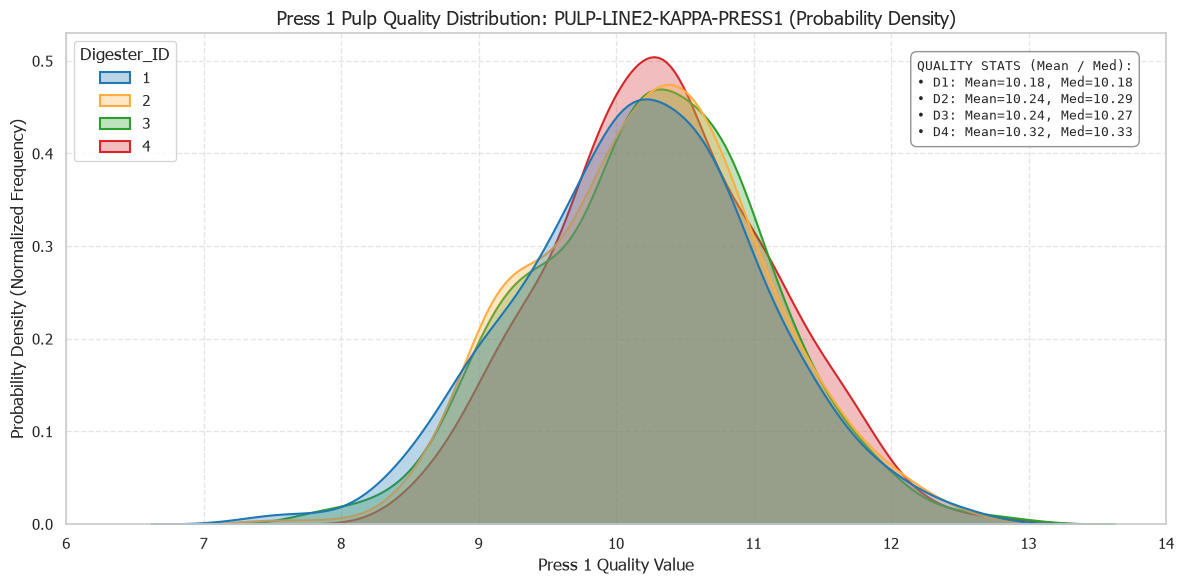

In [32]:
# Identify Press 1 quality parameter columns
kappa_col = [c for c in df_wide.columns if 'KAPPA' in c.upper() or 'Kappa' in c][0] if any('KAPPA' in c.upper() or 'Kappa' in c for c in df_wide.columns) else None
cons_col = [c for c in df_wide.columns if 'Press 1 Feed Cons' in c or 'CONS' in c.upper()][0] if any('CONS' in c.upper() for c in df_wide.columns) else None

palette = {1: '#1f77b4', 2: "#ffad41", 3: '#2ca02c', 4: '#d62728'}
digester_order = [1, 2, 3, 4]

# 1. Plot Kappa / Quality Metric Bell Curve
plt.figure(figsize=(12, 6))
if kappa_col and kappa_col in df_wide.columns:
    ax = sns.kdeplot(
        data=df_wide.dropna(subset=[kappa_col]),
        x=kappa_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
        
    )
    plt.xlim(6, 14)  # Compress X-axis view
    
    # Calculate Mean and Median per Digester
    valid_data = df_wide.dropna(subset=[kappa_col])
    stats_text = "QUALITY STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][kappa_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• D{dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Quality Distribution: {kappa_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Quality Value', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print(" Kappa column not found in dataset. Please verify tag mapping.")

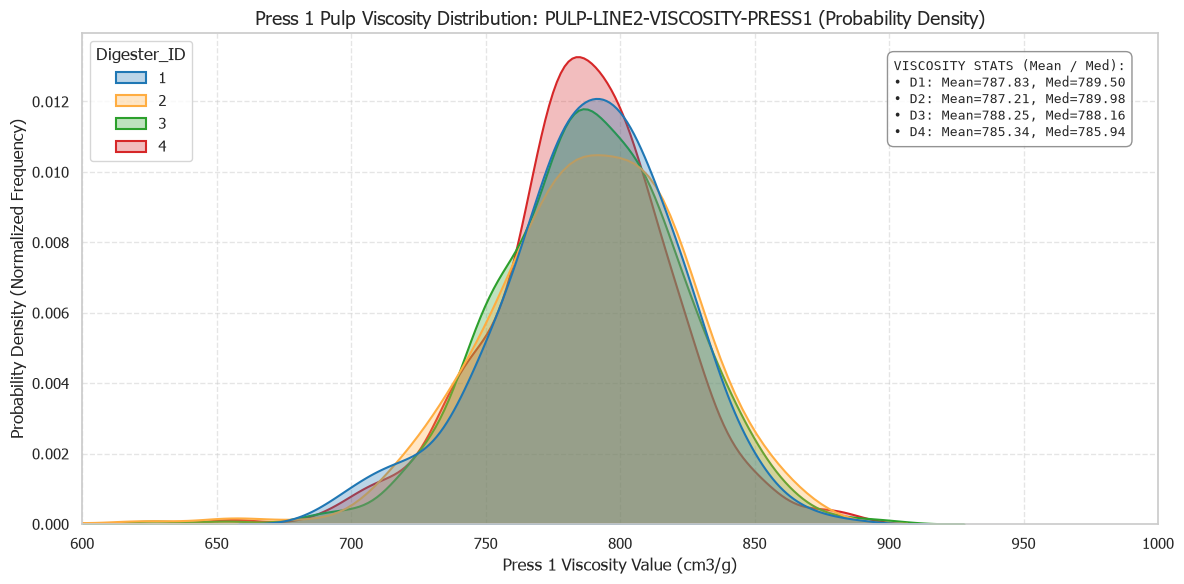

In [33]:
# 2. Plot Viscosity Bell Curve
visc_col = [c for c in df_wide.columns if 'VISCOSITY' in c.upper() or 'Viscosity' in c][0] if any('VISCOSITY' in c.upper() or 'Viscosity' in c for c in df_wide.columns) else None

# Drop sensor spikes before plotting (same range as histogram/boxplot cells)
VISC_FILTER = (400, 2000)
# Adjustable X-axis view range (set to None for auto-scaling)
VISC_XLIM_MIN = 600
VISC_XLIM_MAX = 1000

plt.figure(figsize=(12, 6))
if visc_col and visc_col in df_wide.columns:
    visc_data = df_wide.dropna(subset=[visc_col])
    visc_data = visc_data[(visc_data[visc_col] >= VISC_FILTER[0]) & (visc_data[visc_col] <= VISC_FILTER[1])]
    ax = sns.kdeplot(
        data=visc_data,
        x=visc_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
    )

    if VISC_XLIM_MIN is not None and VISC_XLIM_MAX is not None:
        plt.xlim(VISC_XLIM_MIN, VISC_XLIM_MAX)
    
    # Calculate Mean and Median per Digester (from spike-filtered data)
    valid_data = visc_data
    stats_text = "VISCOSITY STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][visc_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• D{dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Viscosity Distribution: {visc_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Viscosity Value (cm3/g)', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print(" Viscosity column not found in dataset. Please verify tag mapping.")


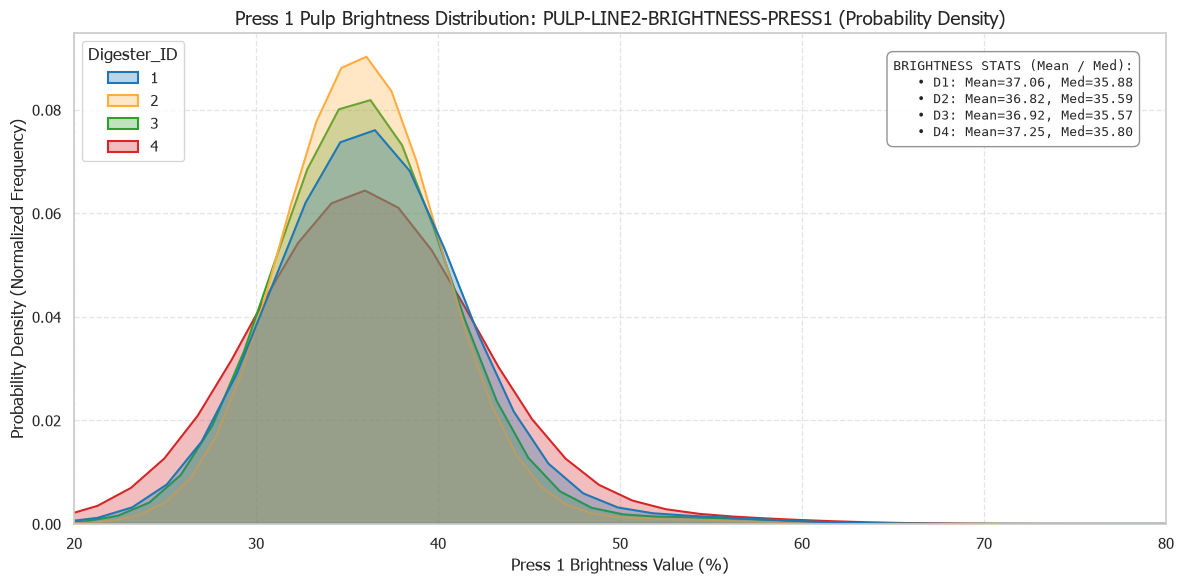

In [34]:
# 3. Plot Brightness Bell Curve
bright_col = [c for c in df_wide.columns if 'BRIGHTNESS' in c.upper() or 'Brightness' in c][0] if any('BRIGHTNESS' in c.upper() or 'Brightness' in c for c in df_wide.columns) else None

plt.figure(figsize=(12, 6))
if bright_col and bright_col in df_wide.columns:
    ax = sns.kdeplot(
        data=df_wide.dropna(subset=[bright_col]),
        x=bright_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
    )
    
    # Calculate Mean and Median per Digester
    valid_data = df_wide.dropna(subset=[bright_col])
    stats_text = "BRIGHTNESS STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][bright_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• D{dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Brightness Distribution: {bright_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Brightness Value (%)', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xlim(20, 80)
    plt.tight_layout()
    plt.show()
else:
    print(" Brightness column not found in dataset. Please verify tag mapping.")

In [35]:
# Reusable helper: plot a single standard histogram with Mean, Median & SOP band
def plot_quality_histogram(col, label, color, xlim=None, ylim=None, filter_lo=None, filter_hi=None, bins=40, density=False):
    if not col or col not in df_wide.columns:
        print(f" {label} column not found in dataset.")
        return

    ylabel = 'Density (normalized)' if density else 'Frequency (count)'
    vals = df_wide[col].dropna()
    if filter_lo is not None and filter_hi is not None:
        vals = vals[(vals >= filter_lo) & (vals <= filter_hi)]  # drop sensor spikes

    mu, sd = vals.mean(), vals.std()
    lo2, hi2 = mu - 2 * sd, mu + 2 * sd  # 2-sigma band (~95% of data)

    plt.figure(figsize=(10, 5))
    plt.hist(vals, bins=bins, color=color, edgecolor='black', alpha=0.75, density=density)
    plt.axvline(mu, color='red', linestyle='--', linewidth=1.5, label=f'Mean = {mu:.2f}')
    plt.axvline(vals.median(), color='black', linestyle=':', linewidth=1.5, label=f'Median = {vals.median():.2f}')
    plt.axvspan(lo2, hi2, color='purple', alpha=0.08, label=f'±2σ [{lo2:.2f}, {hi2:.2f}]')
    plt.axvline(lo2, color='purple', linestyle='-.', linewidth=1.0)
    plt.axvline(hi2, color='purple', linestyle='-.', linewidth=1.0)

    if col in LAB_SOP_LIMITS:
        sop_lo, sop_hi = LAB_SOP_LIMITS[col]
        plt.axvspan(sop_lo, sop_hi, color='green', alpha=0.12, label=f'SOP {sop_lo}-{sop_hi}')

    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)

    plt.title(f'{label} Histogram  (N = {len(vals)})', fontsize=13, fontweight='normal')
    plt.xlabel(label, fontsize=11)
    plt.ylabel(ylabel, fontsize=11)
    plt.legend(fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


# Reusable helper: 2x2 histograms of one parameter split by Digester (D1-D4)
def plot_quality_hist_by_digester(col, label, color, xlim=None, ylim=None, filter_lo=None, filter_hi=None, bins=40, density=False):
    if not col or col not in df_wide.columns or 'Digester_ID' not in df_wide.columns:
        print(f" {label} column or Digester_ID not found in dataset.")
        return

    ylabel = 'Density (normalized)' if density else 'Frequency (count)'

    digester_order = [1, 2, 3, 4]
    fig, axes = plt.subplots(4, 1, figsize=(10, 16))
    axes = axes.flatten()

    for i, dig in enumerate(digester_order):
        ax = axes[i]
        vals = df_wide[df_wide['Digester_ID'] == dig][col].dropna()
        if filter_lo is not None and filter_hi is not None:
            vals = vals[(vals >= filter_lo) & (vals <= filter_hi)]  # drop sensor spikes

        if len(vals) == 0:
            ax.text(0.5, 0.5, f'No data for D{dig}', ha='center', va='center', color='gray')
            ax.set_title(f'D{dig}', fontsize=12)
            continue

        mu, sd = vals.mean(), vals.std()
        lo2, hi2 = mu - 2 * sd, mu + 2 * sd  # 2-sigma band (~95% of data)

        ax.hist(vals, bins=bins, color=color, edgecolor='black', alpha=0.75, density=density)
        ax.axvline(mu, color='red', linestyle='--', linewidth=1.5, label=f'Mean = {mu:.2f}')
        ax.axvline(vals.median(), color='black', linestyle=':', linewidth=1.5, label=f'Median = {vals.median():.2f}')
        ax.axvspan(lo2, hi2, color='purple', alpha=0.08, label=f'±2σ [{lo2:.2f}, {hi2:.2f}]')
        ax.axvline(lo2, color='purple', linestyle='-.', linewidth=1.0)
        ax.axvline(hi2, color='purple', linestyle='-.', linewidth=1.0)

        if col in LAB_SOP_LIMITS:
            sop_lo, sop_hi = LAB_SOP_LIMITS[col]
            ax.axvspan(sop_lo, sop_hi, color='green', alpha=0.12, label=f'SOP {sop_lo}-{sop_hi}')

        if xlim is not None:
            ax.set_xlim(xlim)
        if ylim is not None:
            ax.set_ylim(ylim)

        ax.set_title(f'D{dig}  (N = {len(vals)})', fontsize=12, fontweight='normal')
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=10)
        ax.legend(fontsize=8)
        ax.grid(True, linestyle='--', alpha=0.4)

    fig.suptitle(f'{label} Histogram by Digester (D1 - D4)', fontsize=15)
    plt.tight_layout()
    plt.show()


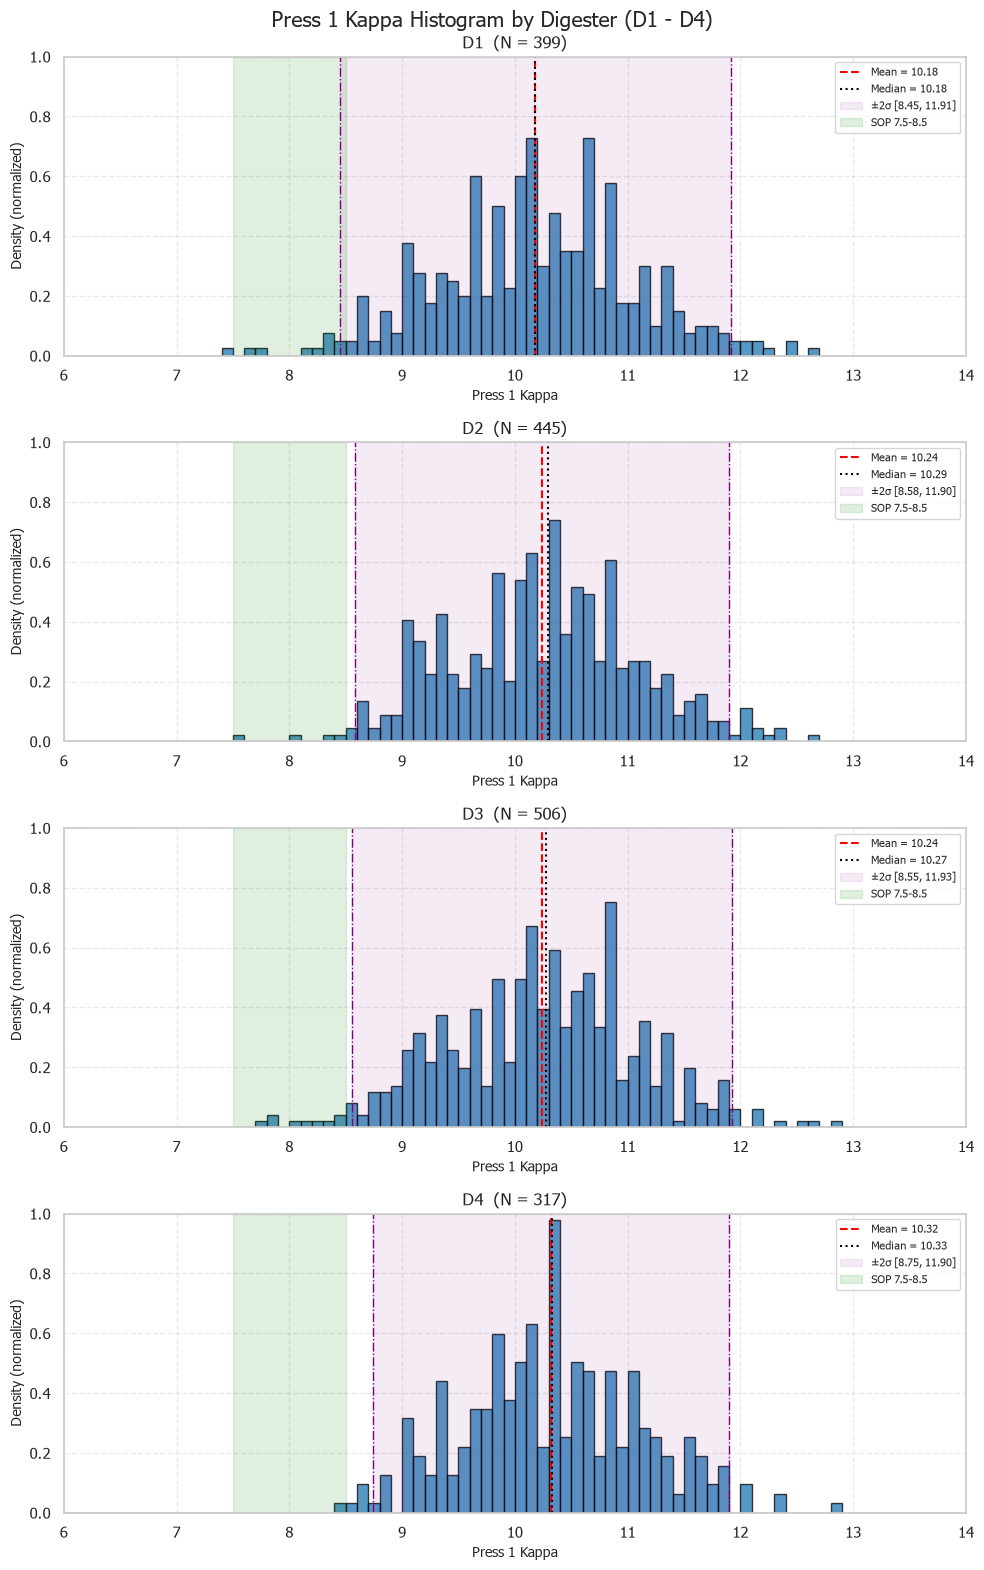

In [36]:
# Kappa Histogram — adjust KAPPA_XLIM to zoom the X-axis (None = auto)
# KAPPA_BIN_WIDTH sets the resolution (smaller = finer).
KAPPA_XLIM = (6, 14)
KAPPA_YLIM = (0, 1)  # density scale; e.g. (0, 1.2) to fix the Y-axis; None = auto
KAPPA_BIN_WIDTH = 0.1
import numpy as np
_kvals = df_wide[kappa_col].dropna()
_lo, _hi = (KAPPA_XLIM if KAPPA_XLIM else (_kvals.min(), _kvals.max()))
kappa_bins = np.arange(_lo, _hi + KAPPA_BIN_WIDTH, KAPPA_BIN_WIDTH)
plot_quality_hist_by_digester(kappa_col, 'Press 1 Kappa', '#1f77b4', xlim=KAPPA_XLIM, ylim=KAPPA_YLIM, bins=kappa_bins, density=True)


In [37]:
# Summary table: Mean, Median, ±2σ and SOP per Digester (same data as the histogram above)
def quality_summary_table(col, filter_lo=None, filter_hi=None):
    sop_lo, sop_hi = LAB_SOP_LIMITS.get(col, (np.nan, np.nan))
    groups = [(f'D{d}', df_wide[df_wide['Digester_ID'] == d][col]) for d in [1, 2, 3, 4]]
    groups.append(('All', df_wide[df_wide['Digester_ID'].isin([1, 2, 3, 4])][col]))
    rows = []
    for name, vals in groups:
        vals = vals.dropna()
        if filter_lo is not None and filter_hi is not None:
            vals = vals[(vals >= filter_lo) & (vals <= filter_hi)]  # drop sensor spikes
        mu, sd = vals.mean(), vals.std()
        rows.append({
            'Digester': name,
            'N': len(vals),
            'Mean': mu,
            'Median': vals.median(),
            'SD (σ)': sd,
            '-2σ': mu - 2 * sd,
            '+2σ': mu + 2 * sd,
            'SOP Low': sop_lo,
            'SOP High': sop_hi,
            '% in SOP': vals.between(sop_lo, sop_hi).mean() * 100,
        })
    return pd.DataFrame(rows).set_index('Digester').round(2)

kappa_summary = quality_summary_table(kappa_col)
display(kappa_summary)


,N,Mean,Median,SD (σ),-2σ,+2σ,SOP Low,SOP High,% in SOP
Digester,,,,,,,,,
D1,399,10.18,10.18,0.87,8.45,11.91,7.5,8.5,2.51
D2,445,10.24,10.29,0.83,8.58,11.90,7.5,8.5,0.90
D3,506,10.24,10.27,0.84,8.55,11.93,7.5,8.5,1.78
D4,317,10.32,10.33,0.79,8.75,11.90,7.5,8.5,0.32
All,1667,10.24,10.25,0.84,8.57,11.91,7.5,8.5,1.44


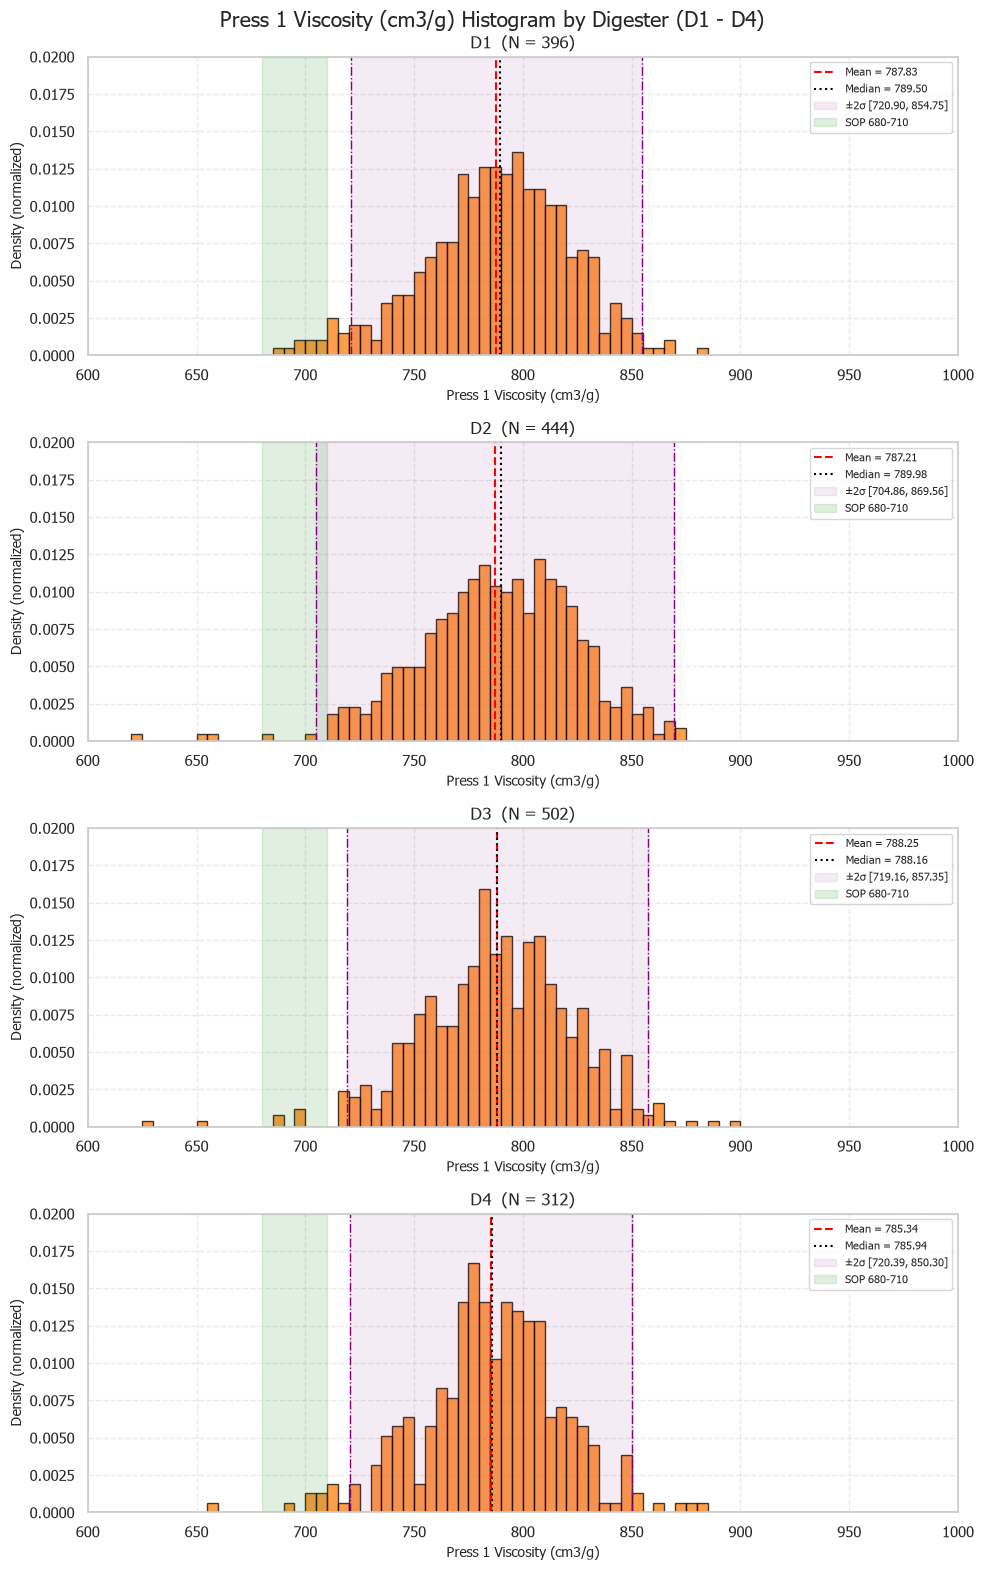

In [38]:
# Viscosity Histogram — adjust VISC_XLIM to zoom the X-axis (None = auto)
# VISC_BIN_WIDTH sets the resolution (smaller = finer).
VISC_XLIM = (600, 1000)
VISC_YLIM = (0, 0.02)  # density scale; e.g. (0, 0.02) to fix the Y-axis; None = auto
VISC_BIN_WIDTH = 5
import numpy as np
_vvals = df_wide[visc_col].dropna()
_vvals = _vvals[(_vvals >= 400) & (_vvals <= 2000)]
_lo, _hi = (VISC_XLIM if VISC_XLIM else (_vvals.min(), _vvals.max()))
visc_bins = np.arange(_lo, _hi + VISC_BIN_WIDTH, VISC_BIN_WIDTH)
plot_quality_hist_by_digester(visc_col, 'Press 1 Viscosity (cm3/g)', '#ff7f0e', xlim=VISC_XLIM, ylim=VISC_YLIM, filter_lo=400, filter_hi=2000, bins=visc_bins, density=True)


In [39]:
# Summary table for Viscosity (same spike filter as the histogram above)
visc_summary = quality_summary_table(visc_col, filter_lo=400, filter_hi=2000)
display(visc_summary)


,N,Mean,Median,SD (σ),-2σ,+2σ,SOP Low,SOP High,% in SOP
Digester,,,,,,,,,
D1,396,787.83,789.50,33.46,720.90,854.75,680,710,2.27
D2,444,787.21,789.98,41.17,704.86,869.56,680,710,0.45
D3,502,788.25,788.16,34.55,719.16,857.35,680,710,1.00
D4,312,785.34,785.94,32.48,720.39,850.30,680,710,1.92
All,1654,787.32,788.30,35.82,715.68,858.97,680,710,1.33


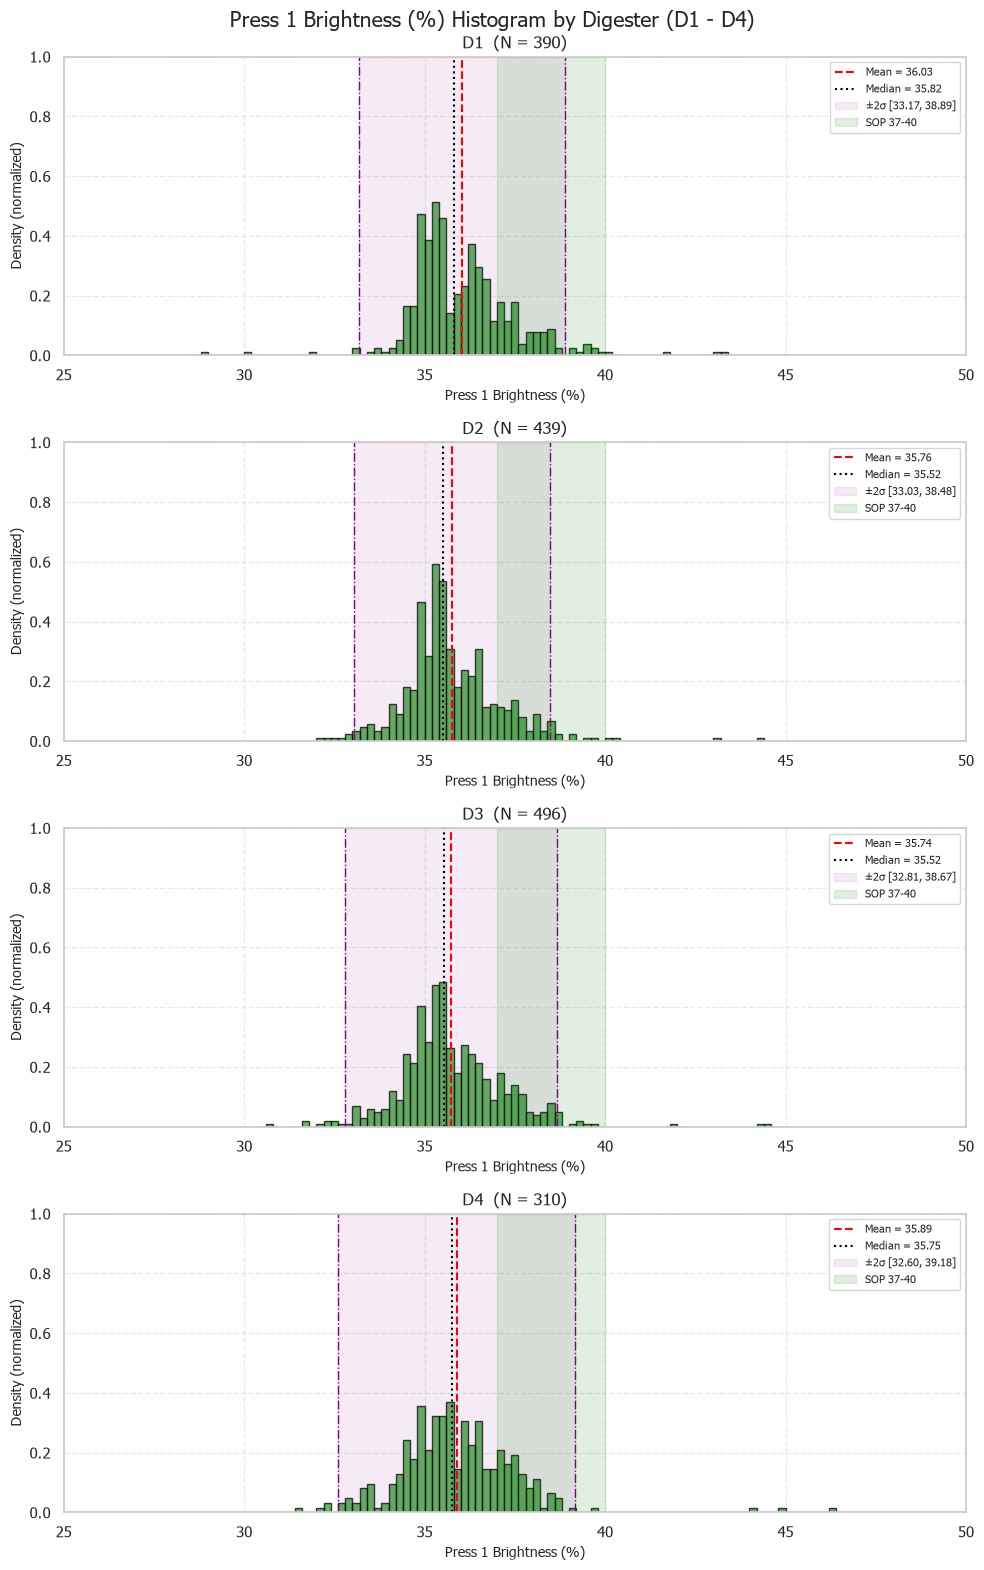

In [40]:
# Brightness Histogram — adjust BRIGHT_XLIM to zoom the X-axis (None = auto)
# BRIGHT_BIN_WIDTH sets the resolution (smaller = finer). 0.2 shows detail around the ~0.5 rounding grid.
BRIGHT_XLIM = (25, 50)
BRIGHT_YLIM = (0, 1)  # density scale; e.g. (0, 0.5) to fix the Y-axis; None = auto
BRIGHT_BIN_WIDTH = 0.2
import numpy as np
_bvals = df_wide[bright_col].dropna()
_bvals = _bvals[(_bvals >= 25) & (_bvals <= 50)]
_lo, _hi = (BRIGHT_XLIM if BRIGHT_XLIM else (_bvals.min(), _bvals.max()))
bright_bins = np.arange(_lo, _hi + BRIGHT_BIN_WIDTH, BRIGHT_BIN_WIDTH)
plot_quality_hist_by_digester(bright_col, 'Press 1 Brightness (%)', '#2ca02c', xlim=BRIGHT_XLIM, ylim=BRIGHT_YLIM, filter_lo=25, filter_hi=50, bins=bright_bins, density=True)


In [41]:
# Summary table for Brightness (same spike filter as the histogram above)
bright_summary = quality_summary_table(bright_col, filter_lo=25, filter_hi=50)
display(bright_summary)


,N,Mean,Median,SD (σ),-2σ,+2σ,SOP Low,SOP High,% in SOP
Digester,,,,,,,,,
D1,390,36.03,35.82,1.43,33.17,38.89,37,40,19.74
D2,439,35.76,35.52,1.36,33.03,38.48,37,40,14.58
D3,496,35.74,35.52,1.47,32.81,38.67,37,40,17.34
D4,310,35.89,35.75,1.65,32.60,39.18,37,40,20.97
All,1635,35.84,35.60,1.47,32.90,38.78,37,40,17.86


### 5b. Lab Quality Boxplots by Digester (D1 - D4)

Box plots compare the spread, median, quartiles (IQR) and outliers of each lab metric across digesters on a single axis, with the SOP band overlaid for reference.


In [42]:
# Reusable helper: boxplot of one parameter split by Digester (D1-D4) with SOP band
def plot_quality_box_by_digester(col, label, color, ylim=None, filter_lo=None, filter_hi=None, showfliers=True):
    if not col or col not in df_wide.columns or 'Digester_ID' not in df_wide.columns:
        print(f" {label} column or Digester_ID not found in dataset.")
        return

    digester_order = [1, 2, 3, 4]
    plot_df = df_wide[['Digester_ID', col]].dropna()
    plot_df['Digester_ID'] = plot_df['Digester_ID'].astype(int)  # float 1.0 would not match order [1, 2, 3, 4]
    if filter_lo is not None and filter_hi is not None:
        plot_df = plot_df[(plot_df[col] >= filter_lo) & (plot_df[col] <= filter_hi)]  # drop sensor spikes

    plt.figure(figsize=(10, 6))
    if col in LAB_SOP_LIMITS:
        sop_lo, sop_hi = LAB_SOP_LIMITS[col]
        plt.axhspan(sop_lo, sop_hi, color='green', alpha=0.12, label=f'SOP {sop_lo}-{sop_hi}')

    ax = sns.boxplot(data=plot_df, x='Digester_ID', y=col, order=digester_order,
                     color=color, showfliers=showfliers, width=0.6)
    ax.set_xticklabels([f'D{i}' for i in digester_order])

    # Annotate median value above each box
    for i, dig in enumerate(digester_order):
        dvals = plot_df[plot_df['Digester_ID'] == dig][col]
        if len(dvals) > 0:
            ax.text(i, dvals.median(), f'{dvals.median():.2f}', ha='center', va='bottom',
                    fontsize=9, fontweight='bold', color='black')

    if ylim is not None:
        plt.ylim(ylim)

    plt.title(f'{label} Boxplot by Digester (D1 - D4)', fontsize=14, fontweight='normal')
    plt.xlabel('Digester ID', fontsize=11)
    plt.ylabel(label, fontsize=11)
    plt.legend(fontsize=9)
    plt.grid(True, axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


C:\Users\chinnput\AppData\Local\Temp\5\ipykernel_104888\453876671.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'D{i}' for i in digester_order])


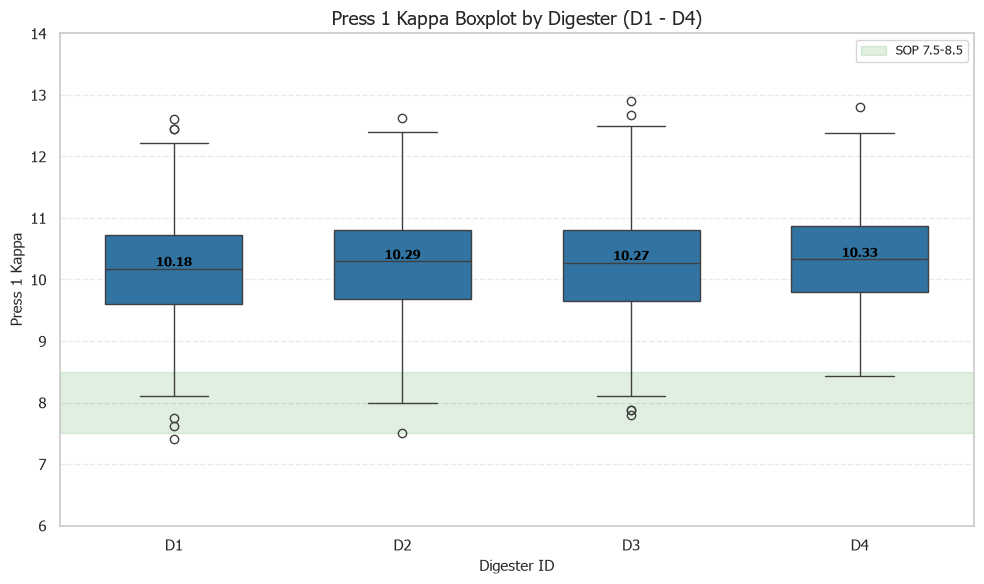

In [43]:
# Kappa Boxplot by Digester — adjust KAPPA_BOX_YLIM to zoom the Y-axis (None = auto)
KAPPA_BOX_YLIM = (6, 14)
plot_quality_box_by_digester(kappa_col, 'Press 1 Kappa', '#1f77b4', ylim=KAPPA_BOX_YLIM)


C:\Users\chinnput\AppData\Local\Temp\5\ipykernel_104888\453876671.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'D{i}' for i in digester_order])


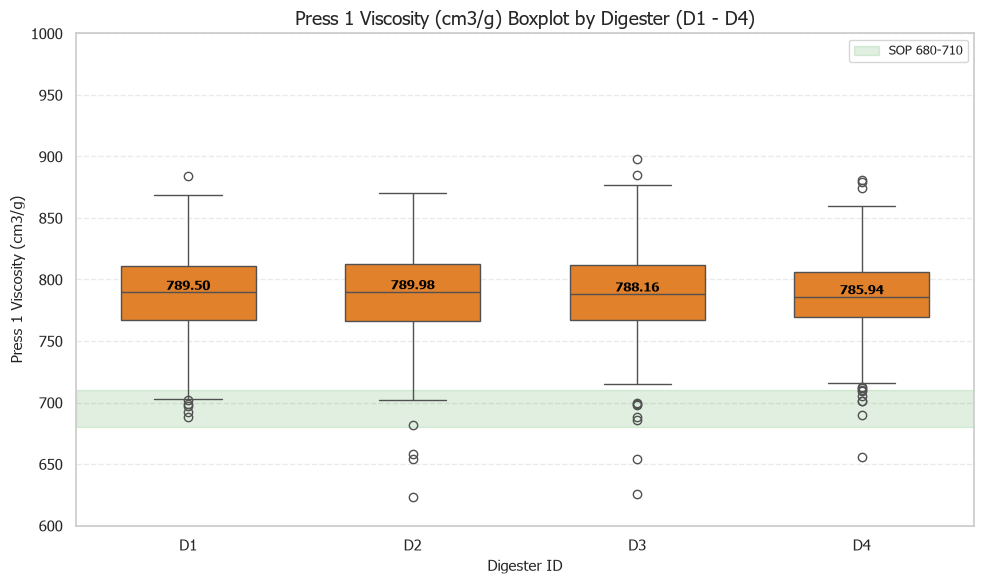

In [44]:
# Viscosity Boxplot by Digester — adjust VISC_BOX_YLIM to zoom the Y-axis (None = auto)
VISC_BOX_YLIM = (600, 1000)
plot_quality_box_by_digester(visc_col, 'Press 1 Viscosity (cm3/g)', '#ff7f0e', ylim=VISC_BOX_YLIM, filter_lo=400, filter_hi=2000)


C:\Users\chinnput\AppData\Local\Temp\5\ipykernel_104888\453876671.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'D{i}' for i in digester_order])


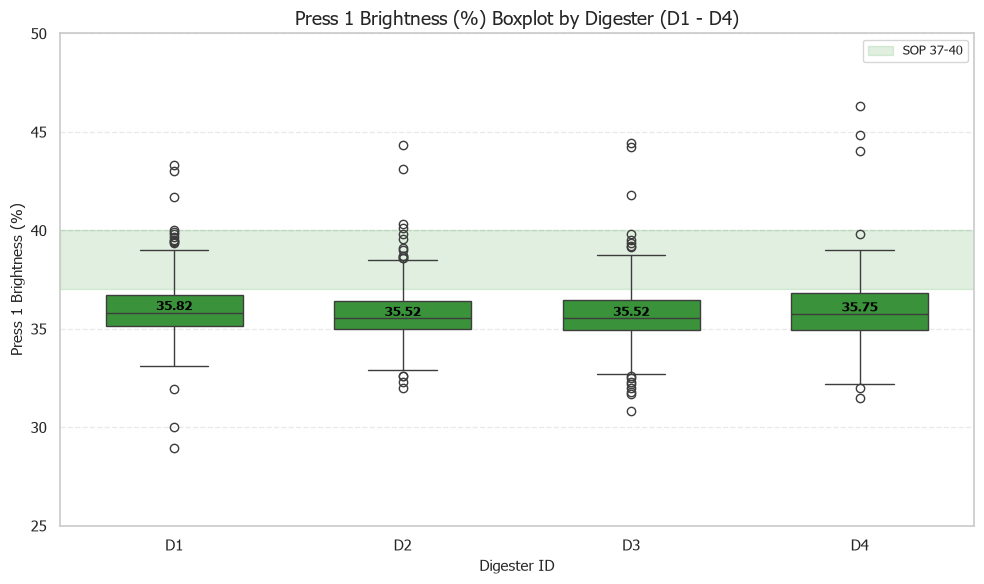

In [45]:
# Brightness Boxplot by Digester — adjust BRIGHT_BOX_YLIM to zoom the Y-axis (None = auto)
BRIGHT_BOX_YLIM = (25, 50)
plot_quality_box_by_digester(bright_col, 'Press 1 Brightness (%)', '#2ca02c', ylim=BRIGHT_BOX_YLIM, filter_lo=25, filter_hi=50)


### 6. Digester Quality Benchmark & Statistical Matrix

In [46]:
# Calculate Mean and Standard Deviation (SD) per Digester (excluding status & metadata)
exclude_keywords = ['STATUS', 'CLUSTER', 'BLOCK_ID', 'ROW_COUNT', 'DURATION_MIN']
numeric_cols = [c for c in df_wide.columns if c not in ['timestamp', 'time', 'Digester_ID'] and not any(kw in c.upper() for kw in exclude_keywords)]

if 'Digester_ID' in df_wide.columns and len(numeric_cols) > 0:
    summary_matrix = df_wide.groupby('Digester_ID')[numeric_cols].agg(['mean', 'std']).T
    print("==========================================================================")
    print("       PRESS 1 QUALITY & PROCESS STATISTICAL BENCHMARK (D1 - D4)          ")
    print("==========================================================================")
    display(summary_matrix)
else:
    print(" Digester ID or numeric process parameters unavailable for aggregation.")

       PRESS 1 QUALITY & PROCESS STATISTICAL BENCHMARK (D1 - D4)          


Digester_ID                                        1.0         2.0  \
tag                                                                  
PM2.104FIQ507                        mean     7.084190    7.435912   
                                     std      8.145987    8.662509   
PM2.105FIC303:MV                     mean     1.621475    1.662695   
                                     std      0.372209    0.352203   
PM2.105NIC207:MV                     mean     3.779420    3.807889   
                                     std      0.614272    0.544536   
PM2.106FIC006:MV                     mean   504.111170  520.628709   
                                     std    116.844910  102.819993   
PM2.305FIC036:MV                     mean     1.028518    1.004067   
                                     std      0.226356    0.233339   
PM2.Prod.ODL                         mean   270.764810  275.257277   
                                     std     51.251993   46.137500   
PULP-LINE2-BRIGHTNESS-PRESS1         mean    37.055957   36.817984   
                                     std     16.273049   14.043979   
PULP-LINE2-KAPPA-PRESS1              mean    10.179948   10.241576   
                                     std      0.866614    0.829345   
PULP-LINE2-VISCOSITY-PRESS1          mean   819.698794  802.702673   
                                     std    482.014562  329.388974   
Specific WHLiqu Consumption (m3_ADT) mean    35.767071    0.262223   
                                     std    511.418387    1.198118   
Specific Steam Consumption (t_ADT)   mean   123.521783    0.343032   
                                     std   1766.826367    2.668308   

Digester_ID                                       3.0         4.0  
tag                                                                
PM2.104FIQ507                        mean    7.588975    6.930732  
                                     std     8.710333    8.794615  
PM2.105FIC303:MV                     mean    1.638362    1.808686  
                                     std     0.354119    0.342353  
PM2.105NIC207:MV                     mean    3.801867    3.822573  
                                     std     0.544875    0.448906  
PM2.106FIC006:MV                     mean  516.012491  554.227829  
                                     std    97.683916   90.618614  
PM2.305FIC036:MV                     mean    1.041626    0.947929  
                                     std     0.225320    0.237471  
PM2.Prod.ODL                         mean  273.248850  286.417465  
                                     std    46.656756   42.840324  
PULP-LINE2-BRIGHTNESS-PRESS1         mean   36.916096   37.251759  
                                     std    15.758478   18.529586  
PULP-LINE2-KAPPA-PRESS1              mean   10.240331   10.324416  
                                     std     0.844354    0.789045  
PULP-LINE2-VISCOSITY-PRESS1          mean  802.445029  840.673911  
                                     std   245.916660  536.948787  
Specific WHLiqu Consumption (m3_ADT) mean    0.221255    0.133606  
                                     std     1.051992    0.651160  
Specific Steam Consumption (t_ADT)   mean    4.486482    1.576011  
                                     std    91.240678   25.460112

### 7. Press 1 & Process Parameter Heatmap by Digester

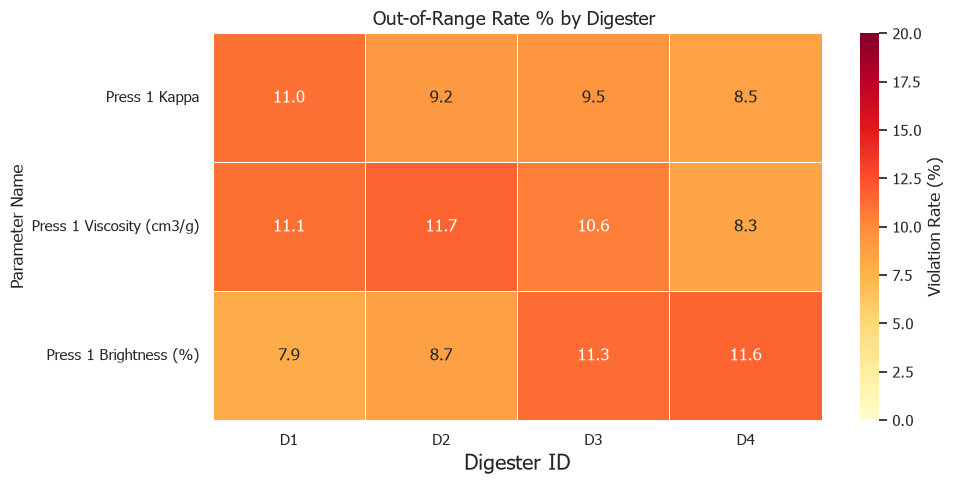

In [47]:
# 2. Plot Process Variation Heatmap: SOP Violation Rate % by Digester

# Friendly Name Mapping for PI Tags & Process Parameters
TAG_LABELS = {
    "PM2.105FIC303:MV": "White Liquor Flow (m3/h)",
    "PM2.305FIC036:MV": "MP Steam Flow (t/h)",
    "PM2.104FIQ507": "LP Steam Flow (t/h)",
    "PM2.Prod.ODL": "Production ODL (ADT/D)",
    "PM2.105NIC207:MV": "Press 1 Feed Cons (%)",
    "PM2.106FIC006:MV": "Deknotting Feed Flow (m3/h)",
    "Specific WHLiqu Consumption (m3_ADT)": "Specific White Liquor (m3/ADT)",
    "Specific Steam Consumption (t_ADT)": "Specific Steam (t/ADT)",
    "PULP-LINE2-KAPPA-PRESS1": "Press 1 Kappa",
    "PULP-LINE2-VISCOSITY-PRESS1": "Press 1 Viscosity (cm3/g)",
    "PULP-LINE2-BRIGHTNESS-PRESS1": "Press 1 Brightness (%)",
    # Mappings for local fallback dataset
    "WHLiqu to DilSrew_White liquor (m3/h)_mean": "White Liquor Flow (m3/h)",
    "MP Steam Pulp Heat_Feed before Reactor 2 (t/h)_mean": "MP Steam Flow (t/h)",
    "Production ODL (ADT/D)_mean": "Production ODL (ADT/D)",
    "Press 1 Feed Cons (%)_mean": "Press 1 Feed Cons (%)",
    "Deknotting Feed Flow (m3/h)_mean": "Deknotting Feed Flow (m3/h)",
    "Specific WHLiqu Consumption (m3_ADT)_mean": "Specific White Liquor (m3/ADT)",
    "Specific Steam Consumption (t_ADT)_mean": "Specific Steam (t/ADT)",
    "Pre O2 Kappa_Kappa online (%)_mean": "Pre O2 Kappa Online",
    "Post O2 Kappa_Kappa online (%)_mean": "Post O2 Kappa Online"
}

if 'Digester_ID' in df_wide.columns:
    numeric_df = df_wide.select_dtypes(include=[np.number]).copy()
    numeric_df['Digester_ID'] = df_wide['Digester_ID']
    
    # -------------------------------------------------------------
    # Select the specific Parameters or Tags to display in the Heatmap
    # You can add/remove entries in the SELECTED_HEATMAP_TAGS list as needed
    # -------------------------------------------------------------
    SELECTED_HEATMAP_TAGS = [
        # Lab Quality Outputs (primary quality parameters)
        "PULP-LINE2-KAPPA-PRESS1",
        "PULP-LINE2-VISCOSITY-PRESS1",
        "PULP-LINE2-BRIGHTNESS-PRESS1",
        
        # # Specific Consumption (specific energy/chemical usage)
        # "Specific Steam Consumption (t_ADT)",
        # "Specific WHLiqu Consumption (m3_ADT)",
        
        # # Key Process DCS Parameters (main operating parameters)
        # "PM2.305FIC036:MV",   # MP Steam Flow
        # "PM2.105FIC303:MV",   # White Liquor Flow
        # "PM2.Prod.ODL",       # Production ODL
        # "PM2.105NIC207:MV",   # Press 1 Feed Cons
    ]
    
    # Keep only variables that exist in the df_wide dataset
    clean_params = [t for t in SELECTED_HEATMAP_TAGS if t in numeric_df.columns]
    
    # If none are configured, fall back to all numeric columns that are not metadata
    if len(clean_params) == 0:
        exclude_keywords = ['STATUS', 'CLUSTER', 'BLOCK_ID', 'ROW_COUNT', 'DURATION_MIN', '_STD']
        clean_params = [c for c in numeric_df.columns if c != 'Digester_ID' and not any(kw in c.upper() for kw in exclude_keywords)]
    
    # Spike filters to drop sensor false readings before computing percentiles
    PCTL_FILTERS = {
        "PULP-LINE2-VISCOSITY-PRESS1": (400, 2000),
        "PULP-LINE2-BRIGHTNESS-PRESS1": (25, 50),
    }

    # Out-of-range Rate (%) using each parameter's own 5th/95th percentile band
    # computed from the POOLED data (all digesters), so a digester that swings
    # more than the overall norm shows a higher %.
    violation_rates = {}
    for param in clean_params:
        valid_vals = numeric_df[param].dropna()
        if param in PCTL_FILTERS:
            flo, fhi = PCTL_FILTERS[param]
            valid_vals = valid_vals[(valid_vals >= flo) & (valid_vals <= fhi)]
        if len(valid_vals) == 0:
            continue
        low = valid_vals.quantile(0.05)
        high = valid_vals.quantile(0.95)

        param_rates = {}
        for dig in [1, 2, 3, 4]:
            dig_vals = numeric_df[numeric_df['Digester_ID'] == dig][param].dropna()
            if param in PCTL_FILTERS:
                flo, fhi = PCTL_FILTERS[param]
                dig_vals = dig_vals[(dig_vals >= flo) & (dig_vals <= fhi)]
            if len(dig_vals) > 0:
                violations = ((dig_vals < low) | (dig_vals > high)).sum()
                rate = (violations / len(dig_vals)) * 100
                param_rates[dig] = rate
            else:
                param_rates[dig] = np.nan
                
        # Clean & Convert tag to friendly readable label
        display_label = TAG_LABELS.get(param, param[:-5] if param.endswith('_mean') else param)
        violation_rates[display_label] = param_rates
        
    heatmap_data = pd.DataFrame(violation_rates).T
    col_order = [d for d in [1, 2, 3, 4] if d in heatmap_data.columns]
    heatmap_data = heatmap_data[col_order]
    heatmap_data.columns = [f'D{c}' for c in heatmap_data.columns]
    
    if not heatmap_data.empty:
        plt.figure(figsize=(10, max(5, len(heatmap_data) * 0.55)))
        sns.heatmap(
            heatmap_data,
            annot=True,
            fmt=".1f",
            cmap="YlOrRd",
            vmin=0,
            vmax=20,
            linewidths=0.5,
            cbar_kws={'label': 'Violation Rate (%)'}
        )
        plt.title('Out-of-Range Rate % by Digester ', fontsize=14, fontweight='normal')
        plt.xlabel('Digester ID', fontsize=15, fontweight='normal')
        plt.ylabel('Parameter Name', fontsize=12, fontweight='normal')
        plt.tight_layout()
        plt.show()
    else:
        print("No valid process parameters found for out-of-range heatmap plotting.")
else:
    print("Digester_ID column unavailable for heatmap plotting.")

### 9. Digester-Specific Correlation Breakdown (D1, D2, D3, D4)

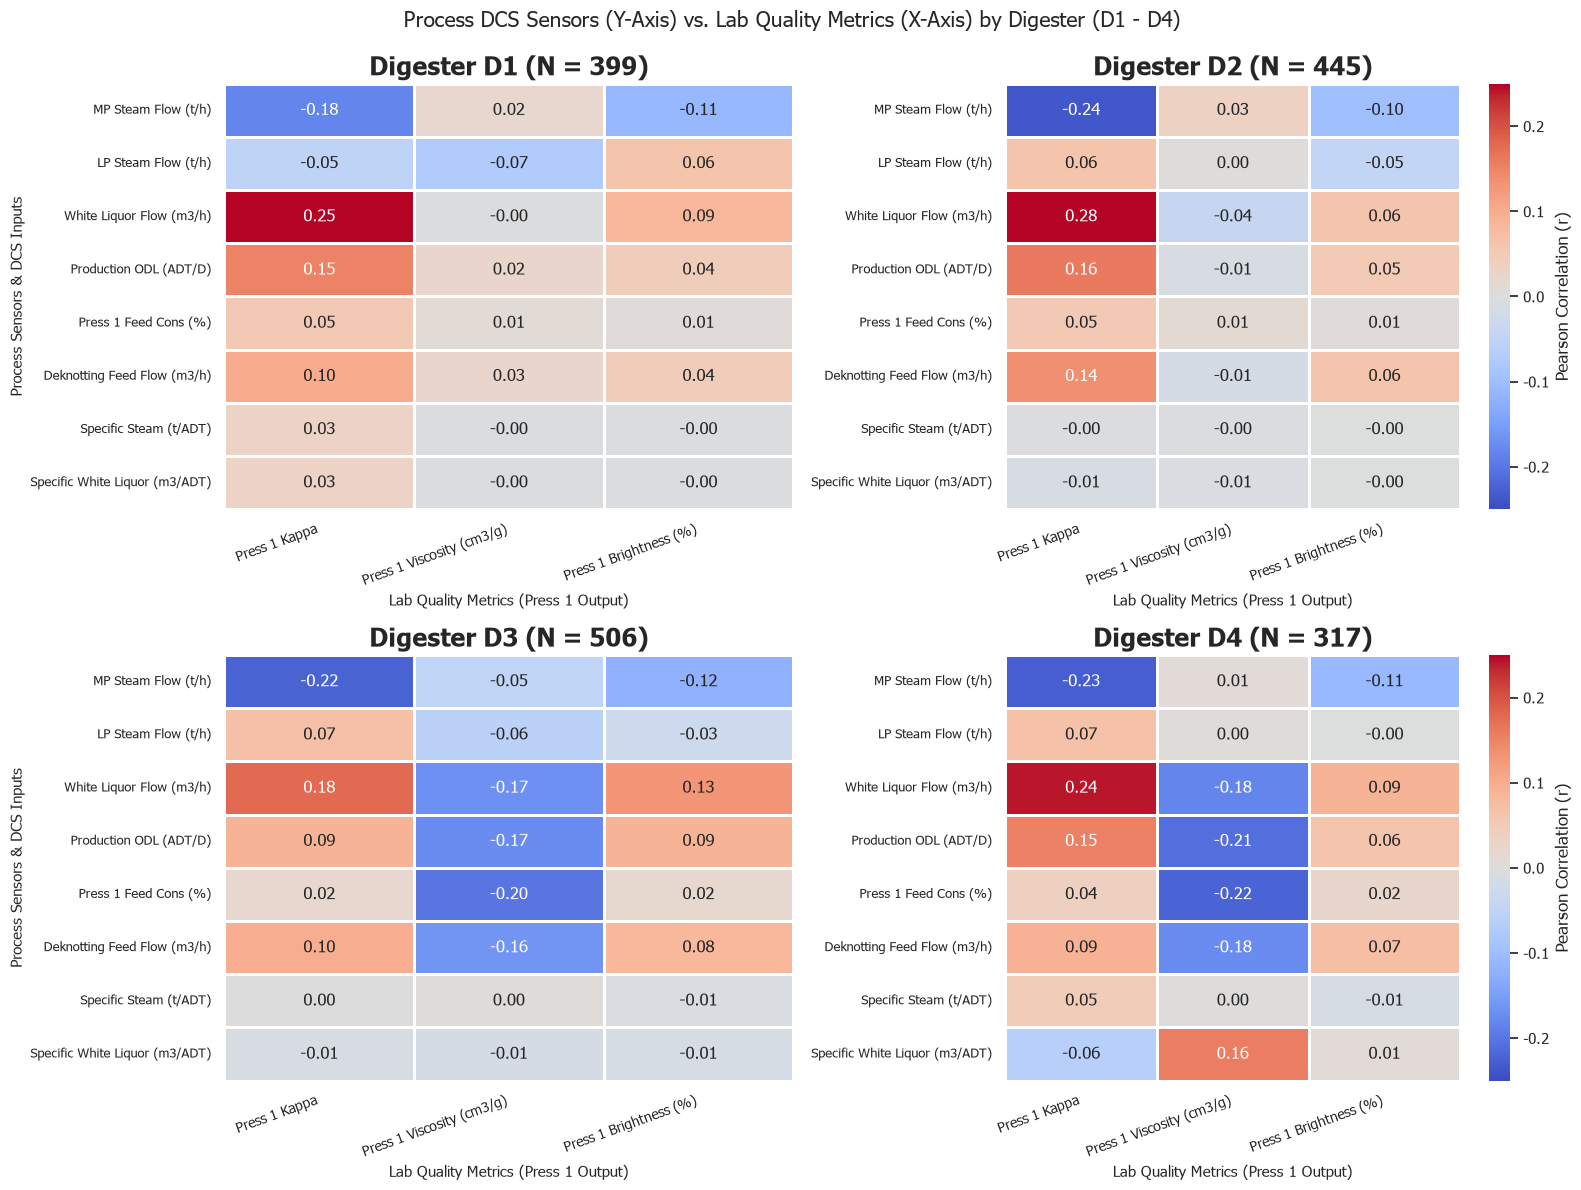

In [50]:
# Plot Digester-Specific Rectangular Cross-Correlation Matrices (Process Sensors vs. Lab Quality)
process_inputs = [
    "PM2.305FIC036:MV",                       # MP Steam Flow
    "PM2.104FIQ507",                          #LP Steam
    "PM2.105FIC303:MV",                       # White Liquor Flow
    "PM2.Prod.ODL",                           # Production ODL
    "PM2.105NIC207:MV",                       # Press 1 Feed Cons
    "PM2.106FIC006:MV",                       # Deknotting Feed Flow
    "Specific Steam Consumption (t_ADT)",     # Specific Steam
    "Specific WHLiqu Consumption (m3_ADT)"    # Specific White Liquor
    
]

lab_outputs = [
    "PULP-LINE2-KAPPA-PRESS1",       # Press 1 Kappa
    "PULP-LINE2-VISCOSITY-PRESS1",   # Press 1 Viscosity
    "PULP-LINE2-BRIGHTNESS-PRESS1"   # Press 1 Brightness
]

# Filter available columns
avail_proc = [c for c in process_inputs if c in df_wide.columns]
avail_lab = [c for c in lab_outputs if c in df_wide.columns]

if 'Digester_ID' in df_wide.columns and len(avail_proc) >= 2 and len(avail_lab) >= 1:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    digester_list = [1, 2, 3, 4]
    
    for idx, dig in enumerate(digester_list):
        ax = axes[idx]
        df_sub = df_wide[df_wide['Digester_ID'] == dig].dropna(how='all')
        
        if len(df_sub) > 5:
            # Compute rectangular cross-correlation: Rows = Process Inputs, Cols = Lab Outputs
            cross_corr = pd.DataFrame(index=avail_proc, columns=avail_lab, dtype=float)
            for p in avail_proc:
                for l in avail_lab:
                    cross_corr.loc[p, l] = df_sub[p].corr(df_sub[l])
            
            # Rename index and columns to friendly labels
            cross_corr_renamed = cross_corr.rename(index=TAG_LABELS, columns=TAG_LABELS)
            
            sns.heatmap(
                cross_corr_renamed,
                annot=True,
                fmt=".2f",
                cmap="coolwarm",
                vmin=-0.25,
                vmax=0.25,
                linewidths=0.8,
                cbar=(idx == 1 or idx == 3),
                cbar_kws={'label': 'Pearson Correlation (r)'} if (idx == 1 or idx == 3) else None,
                ax=ax
            )
            ax.set_title(f'Digester D{dig} (N = {len(df_sub)})', fontsize=18, fontweight='bold')
            ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=10)
            ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
            ax.set_xlabel('Lab Quality Metrics (Press 1 Output)', fontsize=11)
            ax.set_ylabel('Process Sensors & DCS Inputs' if (idx == 0 or idx == 2) else '', fontsize=11)
        else:
            ax.text(0.5, 0.5, f'Insufficient Data for D{dig}\n(N = {len(df_sub)})', 
                    ha='center', va='center', fontsize=12, color='gray')
            ax.set_title(f'Digester D{dig} (No Data)', fontsize=18, fontweight='bold')
            ax.axis('off')
            
    plt.suptitle('Process DCS Sensors (Y-Axis) vs. Lab Quality Metrics (X-Axis) by Digester (D1 - D4)', fontsize=15, y=0.99)
    plt.tight_layout()
    plt.show()
else:
    print(" Digester_ID or required process/lab columns unavailable for rectangular cross-correlation.")


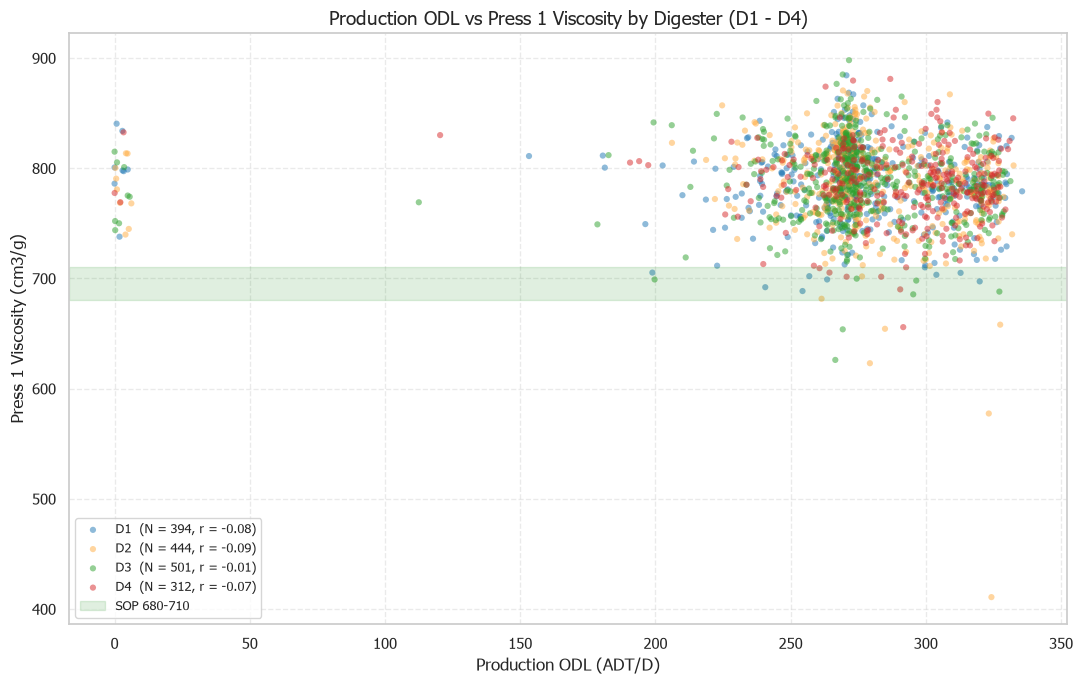

In [51]:
# Scatter: Production ODL vs Press 1 Viscosity, coloured by Digester (D1 - D4)
import numpy as np
import matplotlib.pyplot as plt

# Locate the columns (PI tag name first, then the local-dataset name)
prod_col = next((c for c in df_wide.columns if c == 'PM2.Prod.ODL' or 'Production ODL' in c), None)
visc_col = next((c for c in df_wide.columns if c == 'PULP-LINE2-VISCOSITY-PRESS1' or 'VISCOSITY' in c.upper()), None)

VISC_FILTER = (400, 2000)  # drop sensor spikes, same as the viscosity histogram
scatter_palette = {1: '#1f77b4', 2: "#ffad41", 3: '#2ca02c', 4: '#d62728'}

if prod_col and visc_col and 'Digester_ID' in df_wide.columns:
    sc = df_wide[[prod_col, visc_col, 'Digester_ID']].apply(pd.to_numeric, errors='coerce').dropna()
    sc = sc[(sc[prod_col] > 0) & sc[visc_col].between(*VISC_FILTER) & sc['Digester_ID'].isin([1, 2, 3, 4])]
    sc = sc.assign(Digester_ID=sc['Digester_ID'].astype(int))

    if sc.empty:
        print(" No valid rows for Production ODL vs Viscosity scatter plot.")
    else:
        fig, ax = plt.subplots(figsize=(11, 7))
        for dig in [1, 2, 3, 4]:
            d = sc[sc['Digester_ID'] == dig]
            if d.empty:
                continue
            r = d[prod_col].corr(d[visc_col]) if len(d) > 2 else np.nan
            ax.scatter(d[prod_col], d[visc_col], s=20, alpha=0.5, color=scatter_palette[dig],
                       edgecolor='none', label=f'D{dig}  (N = {len(d)}, r = {r:.2f})')

        # SOP band for viscosity (if defined) for reference
        if visc_col in LAB_SOP_LIMITS:
            sop_lo, sop_hi = LAB_SOP_LIMITS[visc_col]
            ax.axhspan(sop_lo, sop_hi, color='green', alpha=0.12, label=f'SOP {sop_lo}-{sop_hi}')

        ax.set_title('Production ODL vs Press 1 Viscosity by Digester (D1 - D4)', fontsize=14, fontweight='normal')
        ax.set_xlabel('Production ODL (ADT/D)', fontsize=12)
        ax.set_ylabel('Press 1 Viscosity (cm3/g)', fontsize=12)
        ax.legend(fontsize=9, loc='best')
        ax.grid(True, linestyle='--', alpha=0.4)
        plt.tight_layout()
        plt.show()
else:
    print(" Production ODL or Viscosity column (or Digester_ID) not found in dataset. Please verify tag mapping.")


C:\Users\chinnput\AppData\Local\Temp\5\ipykernel_104888\1004250989.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'D{i}' for i in digester_order])


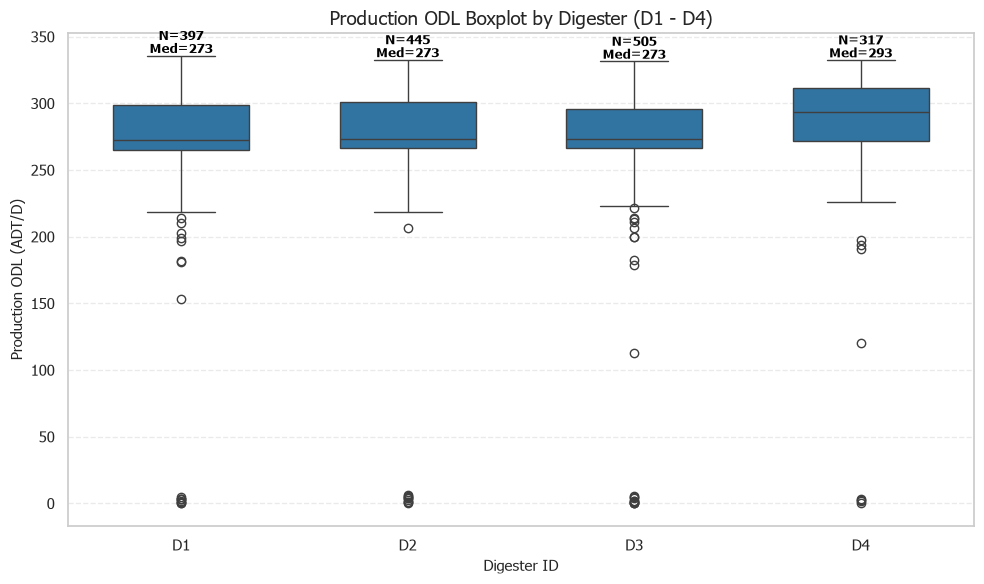

In [52]:
# Boxplot: Production ODL by Digester (D1 - D4)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

prod_col = next((c for c in df_wide.columns if c == 'PM2.Prod.ODL' or 'Production ODL' in c), None)

if prod_col and 'Digester_ID' in df_wide.columns:
    box_df = df_wide[['Digester_ID', prod_col]].apply(pd.to_numeric, errors='coerce').dropna()
    box_df = box_df[(box_df[prod_col] > 0) & box_df['Digester_ID'].isin([1, 2, 3, 4])]
    box_df = box_df.assign(Digester_ID=box_df['Digester_ID'].astype(int))

    if box_df.empty:
        print(" No valid rows for Production ODL boxplot.")
    else:
        digester_order = [1, 2, 3, 4]
        plt.figure(figsize=(10, 6))
        ax = sns.boxplot(data=box_df, x='Digester_ID', y=prod_col, order=digester_order,
                         color='#1f77b4', showfliers=True, width=0.6)
        ax.set_xticklabels([f'D{i}' for i in digester_order])

        # Annotate N and median above each box
        for i, dig in enumerate(digester_order):
            dvals = box_df[box_df['Digester_ID'] == dig][prod_col]
            if len(dvals) > 0:
                ax.text(i, dvals.max(), f'N={len(dvals)}\nMed={dvals.median():.0f}',
                        ha='center', va='bottom', fontsize=9, fontweight='bold', color='black')

        plt.title('Production ODL Boxplot by Digester (D1 - D4)', fontsize=14, fontweight='normal')
        plt.xlabel('Digester ID', fontsize=11)
        plt.ylabel('Production ODL (ADT/D)', fontsize=11)
        plt.grid(True, axis='y', linestyle='--', alpha=0.4)
        plt.tight_layout()
        plt.show()
else:
    print(" Production ODL column or Digester_ID not found in dataset. Please verify tag mapping.")
